<a href="https://colab.research.google.com/github/sureshsabitha2004-boop/DATA-DRIVEN-RECOMMENDATION-FOR-TAILORED-CROP-SELECTION/blob/main/final_crop_recommendation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


🔍 Training Logistic Regression...

🔍 Training Decision Tree...

🔍 Training Random Forest...

🔍 Training Support Vector...

📊 MODEL COMPARISON:

              Model  CV Score  Accuracy  Precision  Recall  F1 Score
      Random Forest    0.9946    0.9919     0.9927  0.9919    0.9919
      Decision Tree    0.9821    0.9838     0.9845  0.9838    0.9834
Logistic Regression    0.9789    0.9757     0.9771  0.9757    0.9759
     Support Vector    0.9854    0.9730     0.9739  0.9730    0.9730


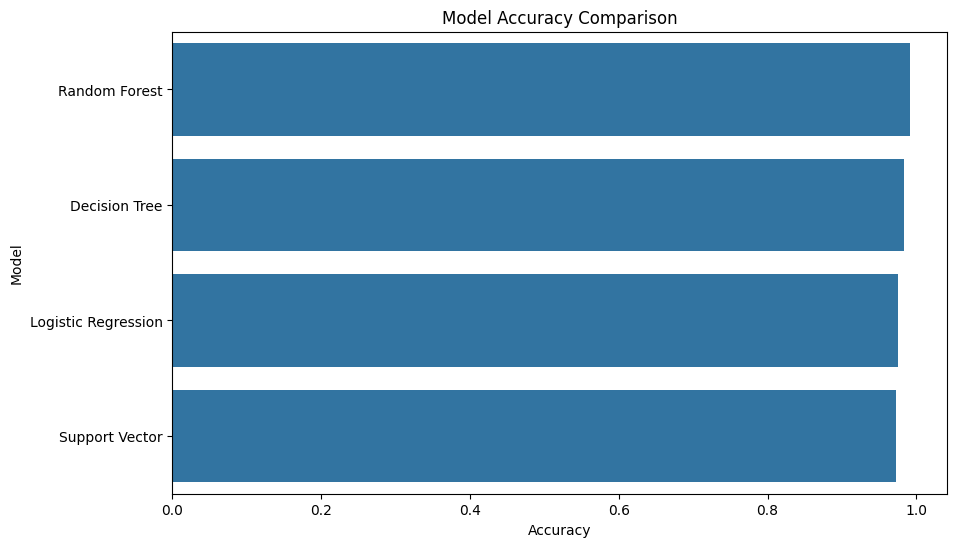


🏆 Best Model: Random Forest

🌱 Prediction: ['rice']


In [17]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


# ===================== LOAD DATA =====================
data = pd.read_csv("/content/Crop_recommendation (1).csv")

# ===================== CLEANING =====================
data = data.drop_duplicates()

X = data.drop("label", axis=1)
y = data["label"]

# Encode labels
le = LabelEncoder()
y = le.fit_transform(y)

# ===================== OUTLIER REMOVAL =====================
def remove_outliers(df):
    df_clean = df.copy()
    for col in df.columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]

    return df_clean

X = remove_outliers(X)
y = y[X.index]

# ===================== SPLIT =====================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ===================== PREPROCESSING =====================
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), X.columns)
])

# ===================== MODELS =====================
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "Support Vector": SVC()

}

# ===================== HYPERPARAMETERS =====================
param_grids = {
    "Logistic Regression": {"model__C": [0.1, 1, 10]},
    "Decision Tree": {"model__max_depth": [5, 10, None]},
    "Random Forest": {"model__n_estimators": [100, 200]},
    "Support Vector": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ['linear', 'rbf']
    }
}

# ===================== TRAIN + EVALUATE =====================
results = []
best_models = {}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    print(f"\n🔍 Training {name}...")

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    grid = GridSearchCV(
        pipeline,
        param_grids[name],
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    best_models[name] = best_model

    # Cross Validation Score
    cv_score = cross_val_score(best_model, X, y, cv=cv).mean()

    # Predictions
    y_pred = best_model.predict(X_test)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    results.append({
        "Model": name,
        "CV Score": round(cv_score, 4),
        "Accuracy": round(acc, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4)
    })

# ===================== RESULTS =====================
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="Accuracy", ascending=False)

print("\n📊 MODEL COMPARISON:\n")
print(results_df.to_string(index=False))

# ===================== VISUALIZATION =====================
plt.figure(figsize=(10, 6))
sns.barplot(x="Accuracy", y="Model", data=results_df)
plt.title("Model Accuracy Comparison")
plt.show()

# ===================== BEST MODEL =====================
best_model_name = results_df.iloc[0]["Model"]
best_model = best_models[best_model_name]

print(f"\n🏆 Best Model: {best_model_name}")

# ===================== SAVE =====================
with open("best_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

with open("label_encoder.pkl", "wb") as f:
    pickle.dump(le, f)

# ===================== PREDICTION =====================
def predict_crop(sample):
    columns = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
    sample_df = pd.DataFrame(sample, columns=columns)

    pred = best_model.predict(sample_df)
    return le.inverse_transform(pred)

# Example
sample = [[90, 42, 43, 20.8, 82.0, 6.5, 202.9]]
print("\n🌱 Prediction:", predict_crop(sample))

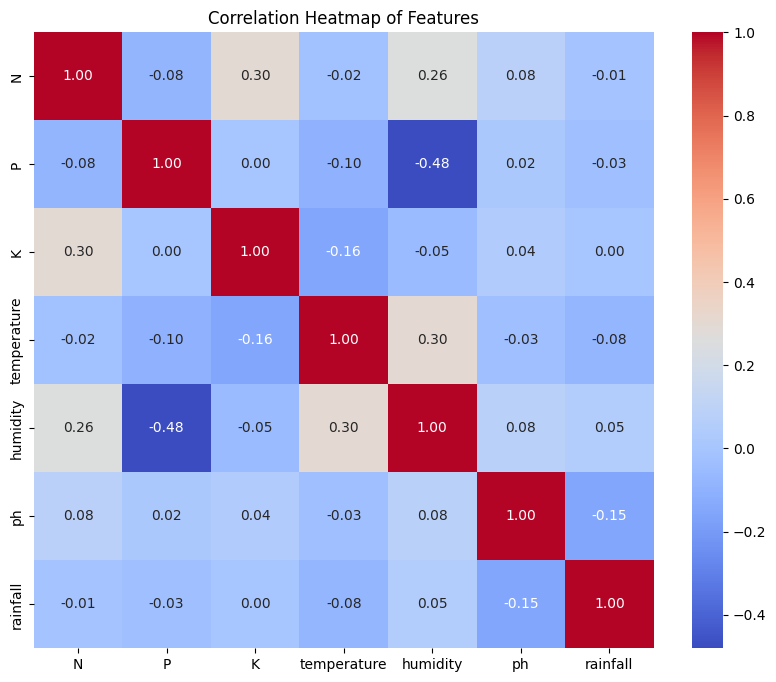

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Features')
plt.show()

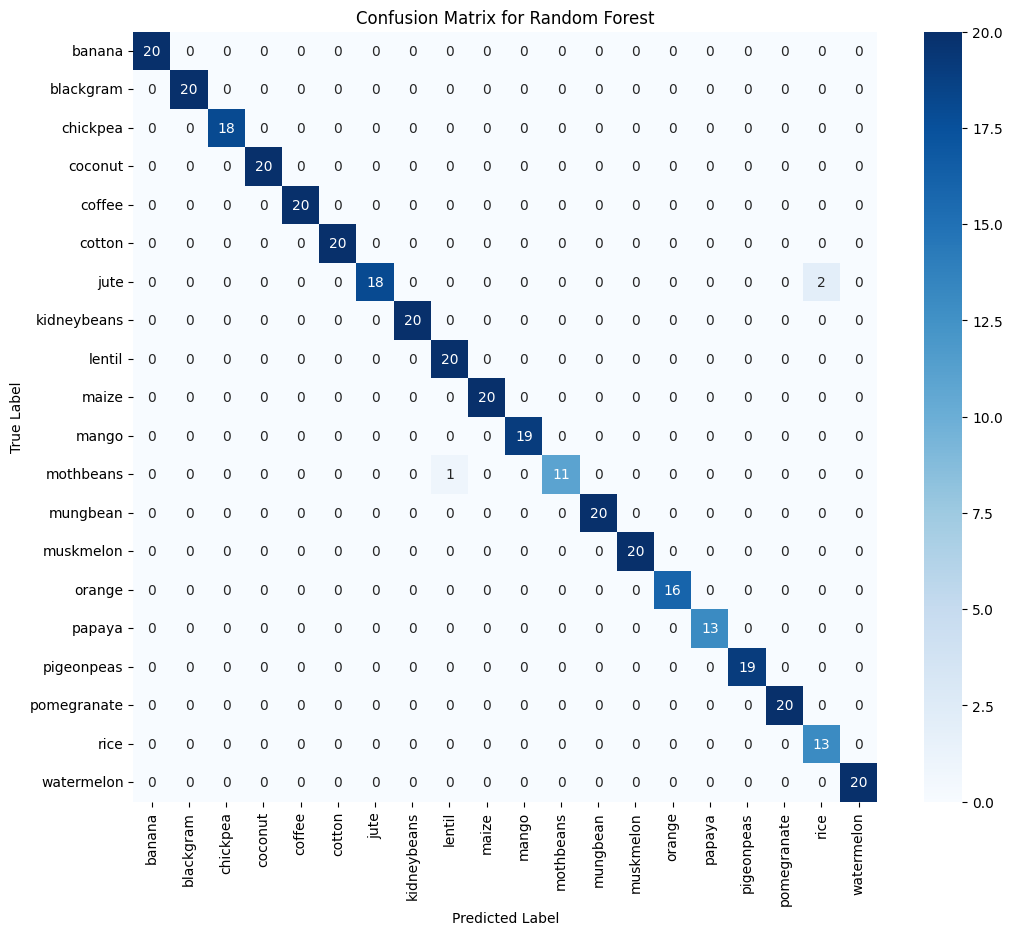

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

# Get the best model and its predictions
best_model_name = results_df.iloc[0]["Model"]
best_model = best_models[best_model_name]
y_pred = best_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.inverse_transform(np.unique(y_test)),
            yticklabels=le.inverse_transform(np.unique(y_test)))
plt.title(f'Confusion Matrix for {best_model_name}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [20]:
from sklearn.metrics import classification_report
import numpy as np

# Get the best model and its predictions
best_model_name = results_df.iloc[0]["Model"]
best_model = best_models[best_model_name]
y_pred = best_model.predict(X_test)

# Print Classification Report
print(f"\nCLASSIFICATION REPORT FOR {best_model_name}:\n")
print(classification_report(
    y_test, y_pred, target_names=le.inverse_transform(np.unique(y_test)), digits=4
))


CLASSIFICATION REPORT FOR Random Forest:

              precision    recall  f1-score   support

      banana     1.0000    1.0000    1.0000        20
   blackgram     1.0000    1.0000    1.0000        20
    chickpea     1.0000    1.0000    1.0000        18
     coconut     1.0000    1.0000    1.0000        20
      coffee     1.0000    1.0000    1.0000        20
      cotton     1.0000    1.0000    1.0000        20
        jute     1.0000    0.9000    0.9474        20
 kidneybeans     1.0000    1.0000    1.0000        20
      lentil     0.9524    1.0000    0.9756        20
       maize     1.0000    1.0000    1.0000        20
       mango     1.0000    1.0000    1.0000        19
   mothbeans     1.0000    0.9167    0.9565        12
    mungbean     1.0000    1.0000    1.0000        20
   muskmelon     1.0000    1.0000    1.0000        20
      orange     1.0000    1.0000    1.0000        16
      papaya     1.0000    1.0000    1.0000        13
  pigeonpeas     1.0000    1.0000    1

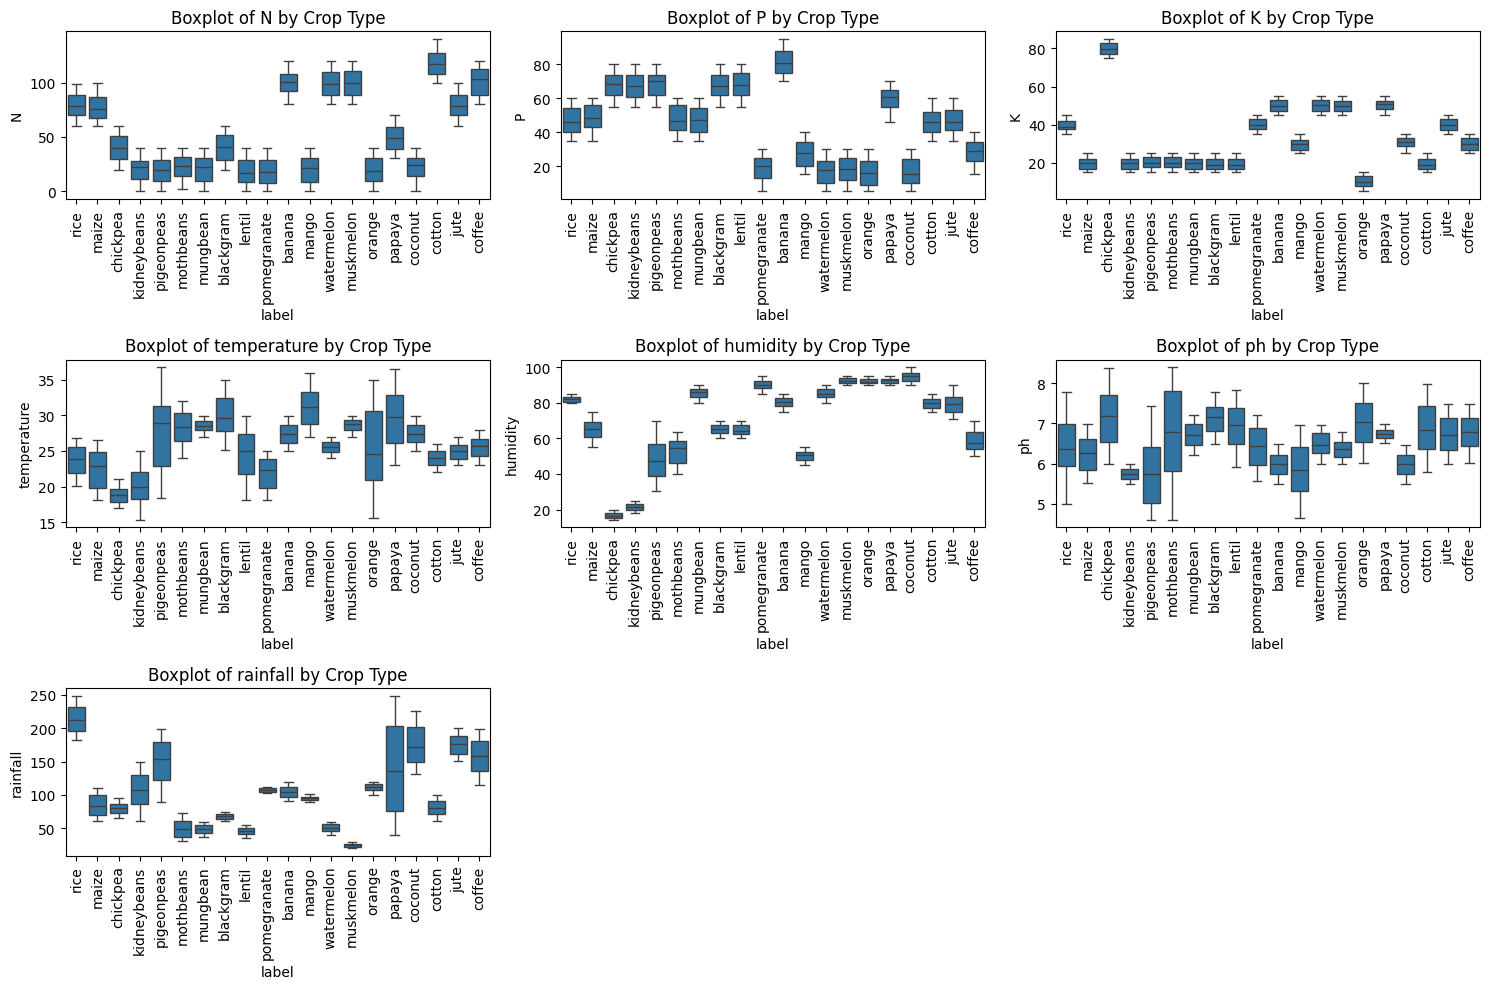

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine X and y for easier plotting of distributions with labels
data_viz = X.copy()
data_viz['label'] = le.inverse_transform(y)

# Boxplots for Feature Distributions
plt.figure(figsize=(15, 10))
for i, col in enumerate(X.columns):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=data_viz[col], x=data_viz['label'])
    plt.title(f'Boxplot of {col} by Crop Type')
    plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

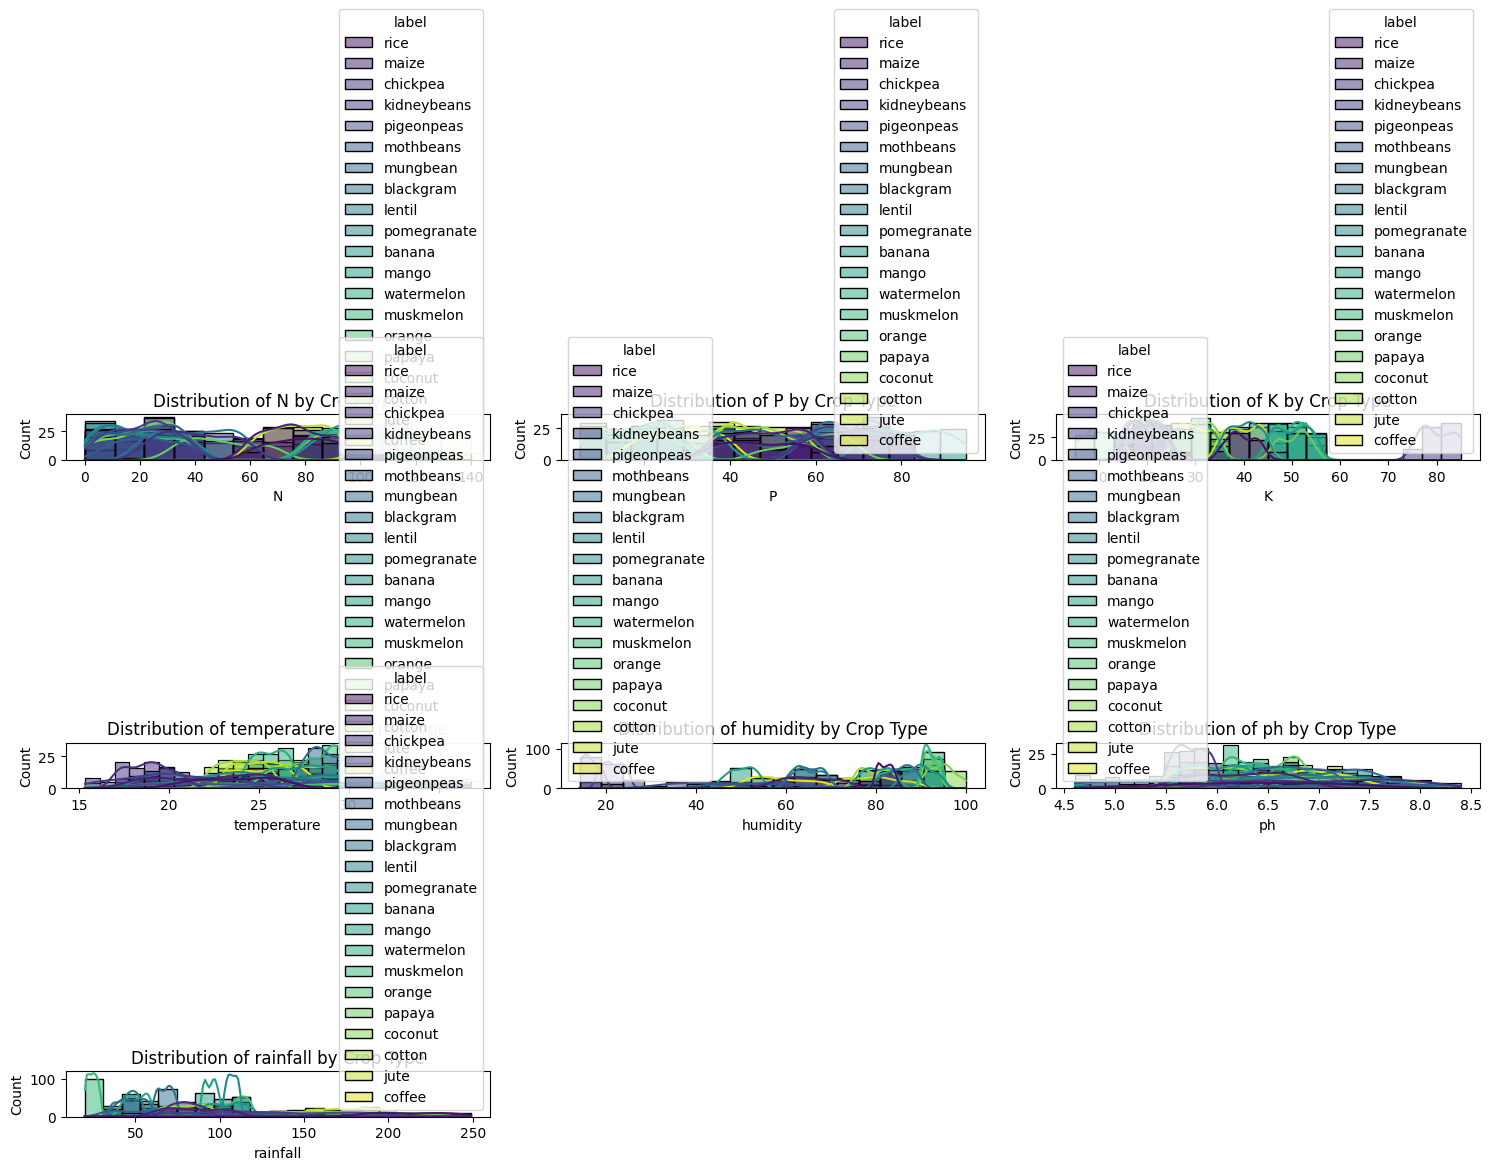

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure data_viz is available (created in previous cells, but good practice to include if running standalone)
if 'data_viz' not in locals():
    data_viz = X.copy()
    data_viz['label'] = le.inverse_transform(y)

# Distribution Charts (Histograms/KDE plots)
plt.figure(figsize=(15, 10))
for i, col in enumerate(X.columns):
    plt.subplot(3, 3, i + 1)
    sns.histplot(data_viz, x=col, hue='label', kde=True, palette='viridis')
    plt.title(f'Distribution of {col} by Crop Type')
plt.tight_layout()
plt.show()